In [35]:
import pandas as pd
import matplotlib.pyplot as plt

In [36]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [37]:
df = pd.read_csv("/content/drive/MyDrive/SEM 7/MACHINE LEARNING II/Coffe_sales.csv")

**Menghitung total penjualan per kategori minuman**

In [38]:
print("\nTanggal awal:", df["Date"].min())
print("Tanggal akhir:", df["Date"].max())

print("\nJumlah catatan per jenis kopi:")
print(
    df["coffee_name"]
    .value_counts()
)


Tanggal awal: 2024-03-01
Tanggal akhir: 2025-03-23

Jumlah catatan per jenis kopi:
coffee_name
Americano with Milk    809
Latte                  757
Americano              564
Cappuccino             486
Cortado                287
Hot Chocolate          276
Cocoa                  239
Espresso               129
Name: count, dtype: int64


**Menghitung penjualan keseluruhan per hari**

In [39]:
penjualan_harian = (
    df.groupby('Date')
    .size()
    .reset_index(name='Jumlah Penjualan')
)

penjualan_harian.head(10)

,Date,Jumlah Penjualan
0,2024-03-01,11
1,2024-03-02,6
2,2024-03-03,9
3,2024-03-04,4
4,2024-03-05,9
5,2024-03-06,4
6,2024-03-07,4
7,2024-03-08,8
8,2024-03-09,13
9,2024-03-10,3


In [40]:
print("Jumlah tanggal unik:", df['Date'].nunique())

Jumlah tanggal unik: 381


**Menghitung jumlah penjualan per tanggal dan kategori waktu**

In [41]:
penjualan_waktu = (
    df.groupby(['Date', 'Time_of_Day'])
    .size()
    .reset_index(name='Jumlah Penjualan')
    .sort_values(['Date', 'Time_of_Day'])
)

display(penjualan_waktu.head(20))

,Date,Time_of_Day,Jumlah Penjualan
0,2024-03-01,Afternoon,6
1,2024-03-01,Morning,1
2,2024-03-01,Night,4
3,2024-03-02,Afternoon,2
4,2024-03-02,Morning,3
5,2024-03-02,Night,1
6,2024-03-03,Afternoon,2
7,2024-03-03,Morning,2
8,2024-03-03,Night,5
9,2024-03-04,Afternoon,1


**Data Time Series per Kategori Waktu**

In [42]:
import pandas as pd

df['Date'] = pd.to_datetime(df['Date'])

semua_tanggal = pd.date_range(
    start=df['Date'].min(),
    end=df['Date'].max(),
    freq='D'
)

kategori_waktu = ['Morning', 'Afternoon', 'Night']

data_per_waktu = {}

for waktu in kategori_waktu:
    data = (
        df[df['Time_of_Day'] == waktu]
        .groupby('Date')
        .size()
        .reindex(semua_tanggal, fill_value=0)
        .rename_axis('ds')
        .reset_index(name='y')
    )

    data_per_waktu[waktu] = data

display(data_per_waktu['Morning'].head())

,ds,y
0,2024-03-01,1
1,2024-03-02,3
2,2024-03-03,2
3,2024-03-04,3
4,2024-03-05,1


In [43]:
import pandas as pd

df['Date'] = pd.to_datetime(df['Date'])

semua_tanggal = pd.date_range(
    start=df['Date'].min(),
    end=df['Date'].max(),
    freq='D'
)

kategori_waktu = ['Morning', 'Afternoon', 'Night']

data_per_waktu = {}

for waktu in kategori_waktu:
    data = (
        df[df['Time_of_Day'] == waktu]
        .groupby('Date')
        .size()
        .reindex(semua_tanggal, fill_value=0)
        .rename_axis('ds')
        .reset_index(name='y')
    )

    data_per_waktu[waktu] = data

display(data_per_waktu['Afternoon'].head())

,ds,y
0,2024-03-01,6
1,2024-03-02,2
2,2024-03-03,2
3,2024-03-04,1
4,2024-03-05,1


In [44]:
import pandas as pd

df['Date'] = pd.to_datetime(df['Date'])

semua_tanggal = pd.date_range(
    start=df['Date'].min(),
    end=df['Date'].max(),
    freq='D'
)

kategori_waktu = ['Morning', 'Afternoon', 'Night']

data_per_waktu = {}

for waktu in kategori_waktu:
    data = (
        df[df['Time_of_Day'] == waktu]
        .groupby('Date')
        .size()
        .reindex(semua_tanggal, fill_value=0)
        .rename_axis('ds')
        .reset_index(name='y')
    )

    data_per_waktu[waktu] = data

display(data_per_waktu['Night'].head())

,ds,y
0,2024-03-01,4
1,2024-03-02,1
2,2024-03-03,5
3,2024-03-04,0
4,2024-03-05,7


**Prediksi Prophet**

In [45]:
!pip install prophet

In [46]:
import pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

(membagi data training dan testing)

In [47]:
hasil_evaluasi = {}

for waktu in kategori_waktu:

    data = data_per_waktu[waktu].copy()
    data = data.sort_values('ds').reset_index(drop=True)

    # Pembagian data secara kronologis: 80% training, 20% testing
    batas = int(len(data) * 0.8)

    train = data.iloc[:batas].copy()
    test = data.iloc[batas:].copy()

    print(f'Kategori waktu: {waktu}')
    print(f'Jumlah data training: {len(train)}')
    print(f'Jumlah data testing: {len(test)}')
    print(f'Periode training: {train["ds"].min()} s.d. {train["ds"].max()}')
    print(f'Periode testing: {test["ds"].min()} s.d. {test["ds"].max()}')
    print('-' * 50)

Kategori waktu: Morning
Jumlah data training: 310
Jumlah data testing: 78
Periode training: 2024-03-01 00:00:00 s.d. 2025-01-04 00:00:00
Periode testing: 2025-01-05 00:00:00 s.d. 2025-03-23 00:00:00
--------------------------------------------------
Kategori waktu: Afternoon
Jumlah data training: 310
Jumlah data testing: 78
Periode training: 2024-03-01 00:00:00 s.d. 2025-01-04 00:00:00
Periode testing: 2025-01-05 00:00:00 s.d. 2025-03-23 00:00:00
--------------------------------------------------
Kategori waktu: Night
Jumlah data training: 310
Jumlah data testing: 78
Periode training: 2024-03-01 00:00:00 s.d. 2025-01-04 00:00:00
Periode testing: 2025-01-05 00:00:00 s.d. 2025-03-23 00:00:00
--------------------------------------------------


(melatih Prophet dan memprediksi data testing)

In [48]:
hasil_evaluasi = {}
model_training = {}

for waktu in kategori_waktu:

    data = data_per_waktu[waktu].copy().sort_values('ds').reset_index(drop=True)

    # Pembagian data training dan testing (80:20)
    batas = int(len(data) * 0.8)
    train = data.iloc[:batas].copy()
    test = data.iloc[batas:].copy()

    # Melatih model Prophet menggunakan data training
    model = Prophet()
    model.fit(train)

    # Prediksi pada periode testing
    future_test = test[['ds']].copy()
    forecast_test = model.predict(future_test)

    # Mengambil nilai aktual dan prediksi
    aktual = test['y'].to_numpy()
    prediksi = forecast_test['yhat'].to_numpy()

    # Evaluasi MAE dan RMSE
    mae = mean_absolute_error(aktual, prediksi)
    rmse = np.sqrt(mean_squared_error(aktual, prediksi))

    # Menghitung MAPE, hanya untuk aktual > 0
    mask = aktual != 0

    if mask.sum() > 0:
        mape = np.mean(
            np.abs((aktual[mask] - prediksi[mask]) / aktual[mask])
        ) * 100
    else:
        mape = np.nan

    # Menyimpan hasil evaluasi
    hasil_evaluasi[waktu] = {
        'MAE': mae,
        'RMSE': rmse,
        'MAPE (%)': mape,
        'Jumlah Data Testing': len(test),
        'Data Aktual Nol': int((aktual == 0).sum())
    }

    model_training[waktu] = model

    print(f'Kategori waktu: {waktu}')
    print(f'MAE  : {mae:.3f}')
    print(f'RMSE : {rmse:.3f}')
    print(f'MAPE : {mape:.2f}%' if not np.isnan(mape) else 'MAPE : tidak dapat dihitung')
    print(f'Data testing dengan aktual nol: {(aktual == 0).sum()}')
    print('-' * 40)

# Menampilkan tabel evaluasi
tabel_evaluasi = pd.DataFrame(hasil_evaluasi).T
display(tabel_evaluasi)

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


Kategori waktu: Morning
MAE  : 2.219
RMSE : 2.835
MAPE : 54.17%
Data testing dengan aktual nol: 7
----------------------------------------


INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


Kategori waktu: Afternoon
MAE  : 2.601
RMSE : 3.418
MAPE : 56.58%
Data testing dengan aktual nol: 7
----------------------------------------
Kategori waktu: Night
MAE  : 2.162
RMSE : 2.570
MAPE : 70.21%
Data testing dengan aktual nol: 15
----------------------------------------


,MAE,RMSE,MAPE (%),Jumlah Data Testing,Data Aktual Nol
Morning,2.218995,2.835104,54.169875,78.0,7.0
Afternoon,2.600806,3.418253,56.584170,78.0,7.0
Night,2.161885,2.570380,70.208563,78.0,15.0


(mmebuat tabel evaluasi)

In [49]:
tabel_evaluasi = pd.DataFrame(hasil_evaluasi).T.reset_index()
tabel_evaluasi = tabel_evaluasi.rename(
    columns={'index': 'Kategori_Waktu'}
)

display(tabel_evaluasi)

,Kategori_Waktu,MAE,RMSE,MAPE (%),Jumlah Data Testing,Data Aktual Nol
0,Morning,2.218995,2.835104,54.169875,78.0,7.0
1,Afternoon,2.600806,3.418253,56.584170,78.0,7.0
2,Night,2.161885,2.570380,70.208563,78.0,15.0


(melatih ulang dengan seluruh data dan memprediksi satu hari ke depan)

In [50]:
hasil_prediksi = []

for waktu in kategori_waktu:

    data = data_per_waktu[waktu].copy().sort_values('ds')

    # Melatih ulang model dengan seluruh data
    model_final = Prophet()
    model_final.fit(data)

    # Prediksi satu hari setelah tanggal terakhir
    future = model_final.make_future_dataframe(
        periods=1,
        freq='D'
    )

    forecast = model_final.predict(future)
    prediksi_besok = forecast.iloc[-1]

    hasil_prediksi.append({
        'Kategori_Waktu': waktu,
        'Tanggal_Prediksi': prediksi_besok['ds'],
        'Prediksi_Penjualan': max(0, round(prediksi_besok['yhat'])),
        'Batas_Bawah': prediksi_besok['yhat_lower'],
        'Batas_Atas': prediksi_besok['yhat_upper']
    })

tabel_prediksi = pd.DataFrame(hasil_prediksi)
display(tabel_prediksi)

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


,Kategori_Waktu,Tanggal_Prediksi,Prediksi_Penjualan,Batas_Bawah,Batas_Atas
0,Morning,2025-03-24,5,1.924304,7.769718
1,Afternoon,2025-03-24,5,1.704228,7.738891
2,Night,2025-03-24,4,0.590027,6.980512


Prediksi ada konfigurasi waktu

In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [53]:
# Parameter Prophet yang digunakan
parameter_prophet = {
    'changepoint_prior_scale': 0.05,
    'seasonality_prior_scale': 10.0,
    'seasonality_mode': 'additive',
    'n_changepoints': 25,
    'weekly_seasonality': True,
    'yearly_seasonality': False,
    'daily_seasonality': False
}

hasil_evaluasi = {}
hasil_prediksi = []
model_training = {}
model_final = {}
hasil_testing = {}

for waktu in kategori_waktu:

    print(f'KATEGORI WAKTU: {waktu}')

    # 1. Menyiapkan data time series
    data = (
        data_per_waktu[waktu]
        .copy()
        .sort_values('ds')
        .reset_index(drop=True)
    )

    # Memastikan format kolom sesuai kebutuhan Prophet
    data['ds'] = pd.to_datetime(data['ds'])
    data['y'] = pd.to_numeric(data['y'])

    # 2. Membagi data training dan testing secara kronologis
    batas = int(len(data) * 0.8)

    train = data.iloc[:batas].copy()
    test = data.iloc[batas:].copy()

    print(f'Jumlah data training: {len(train)}')
    print(f'Jumlah data testing : {len(test)}')
    print(
        f'Periode training: {train["ds"].min().date()} '
        f's.d. {train["ds"].max().date()}'
    )
    print(
        f'Periode testing : {test["ds"].min().date()} '
        f's.d. {test["ds"].max().date()}'
    )

    # 3. Membuat dan melatih model Prophet dengan parameter
    model = Prophet(**parameter_prophet)
    model.fit(train[['ds', 'y']])

    model_training[waktu] = model

    # 4. Memprediksi tanggal pada periode testing
    future_test = test[['ds']].copy()
    forecast_test = model.predict(future_test)

    aktual = test['y'].to_numpy()
    prediksi = forecast_test['yhat'].to_numpy()

    # 5. Menghitung MAE dan RMSE
    mae = mean_absolute_error(aktual, prediksi)

    rmse = np.sqrt(
        mean_squared_error(aktual, prediksi)
    )

    # 6. Menghitung MAPE
    # Nilai aktual nol tidak dimasukkan dalam pembagi MAPE
    mask = aktual != 0

    if mask.sum() > 0:
        mape = np.mean(
            np.abs(
                (aktual[mask] - prediksi[mask]) / aktual[mask]
            )
        ) * 100
    else:
        mape = np.nan

    # 7. Menyimpan hasil evaluasi
    hasil_evaluasi[waktu] = {
        'MAE': mae,
        'RMSE': rmse,
        'MAPE (%)': mape,
        'Jumlah Data Testing': len(test),
        'Jumlah Aktual Nol': int((aktual == 0).sum()),
        'Data untuk MAPE': int(mask.sum())
    }

    # Menyimpan hasil prediksi pada data testing
    hasil_testing[waktu] = pd.DataFrame({
        'ds': test['ds'].to_numpy(),
        'Aktual': aktual,
        'Prediksi': prediksi
    })

    print(f'MAE  : {mae:.3f}')
    print(f'RMSE : {rmse:.3f}')

    if np.isnan(mape):
        print('MAPE : tidak dapat dihitung')
    else:
        print(f'MAPE : {mape:.2f}%')

    print(f'Jumlah aktual nol: {(aktual == 0).sum()}')
    print('-' * 50)

    # 8. Melatih ulang model dengan seluruh data historis
    model_akhir = Prophet(**parameter_prophet)
    model_akhir.fit(data[['ds', 'y']])

    model_final[waktu] = model_akhir

    # 9. Membuat prediksi satu hari setelah data terakhir
    future = model_akhir.make_future_dataframe(
        periods=1,
        freq='D'
    )

    forecast = model_akhir.predict(future)

    prediksi_besok = forecast.iloc[-1]

    hasil_prediksi.append({
        'Kategori_Waktu': waktu,
        'Tanggal_Prediksi': prediksi_besok['ds'],
        'Prediksi_Mentah': prediksi_besok['yhat'],
        'Prediksi_Penjualan': max(
            0, int(np.rint(prediksi_besok['yhat']))
        ),
        'Batas_Bawah': prediksi_besok['yhat_lower'],
        'Batas_Atas': prediksi_besok['yhat_upper']
    })


# 10. Menampilkan tabel evaluasi
tabel_evaluasi = (
    pd.DataFrame(hasil_evaluasi)
    .T
    .rename_axis('Kategori_Waktu')
    .reset_index()
)

print('TABEL EVALUASI MODEL')
display(tabel_evaluasi)


# 11. Menampilkan prediksi satu hari ke depan
tabel_prediksi = pd.DataFrame(hasil_prediksi)

print('PREDIKSI PENJUALAN SATU HARI KE DEPAN')
display(tabel_prediksi)

KATEGORI WAKTU: Morning
Jumlah data training: 310
Jumlah data testing : 78
Periode training: 2024-03-01 s.d. 2025-01-04
Periode testing : 2025-01-05 s.d. 2025-03-23
MAE  : 2.219
RMSE : 2.835
MAPE : 54.17%
Jumlah aktual nol: 7
--------------------------------------------------
KATEGORI WAKTU: Afternoon
Jumlah data training: 310
Jumlah data testing : 78
Periode training: 2024-03-01 s.d. 2025-01-04
Periode testing : 2025-01-05 s.d. 2025-03-23
MAE  : 2.601
RMSE : 3.418
MAPE : 56.58%
Jumlah aktual nol: 7
--------------------------------------------------
KATEGORI WAKTU: Night
Jumlah data training: 310
Jumlah data testing : 78
Periode training: 2024-03-01 s.d. 2025-01-04
Periode testing : 2025-01-05 s.d. 2025-03-23
MAE  : 2.162
RMSE : 2.570
MAPE : 70.21%
Jumlah aktual nol: 15
--------------------------------------------------
TABEL EVALUASI MODEL


,Kategori_Waktu,MAE,RMSE,MAPE (%),Jumlah Data Testing,Jumlah Aktual Nol,Data untuk MAPE
0,Morning,2.218995,2.835104,54.169875,78.0,7.0,71.0
1,Afternoon,2.600806,3.418253,56.584170,78.0,7.0,71.0
2,Night,2.161885,2.570380,70.208563,78.0,15.0,63.0


PREDIKSI PENJUALAN SATU HARI KE DEPAN


,Kategori_Waktu,Tanggal_Prediksi,Prediksi_Mentah,Prediksi_Penjualan,Batas_Bawah,Batas_Atas
0,Morning,2025-03-24,4.640128,5,1.479598,7.404785
1,Afternoon,2025-03-24,4.807600,5,1.705463,7.996460
2,Night,2025-03-24,3.818749,4,0.656936,6.821909


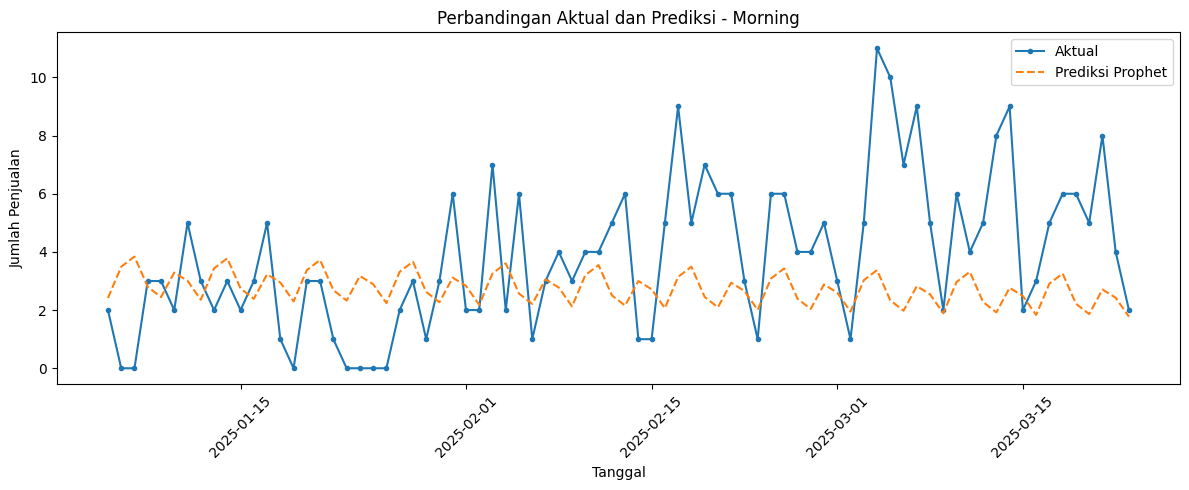

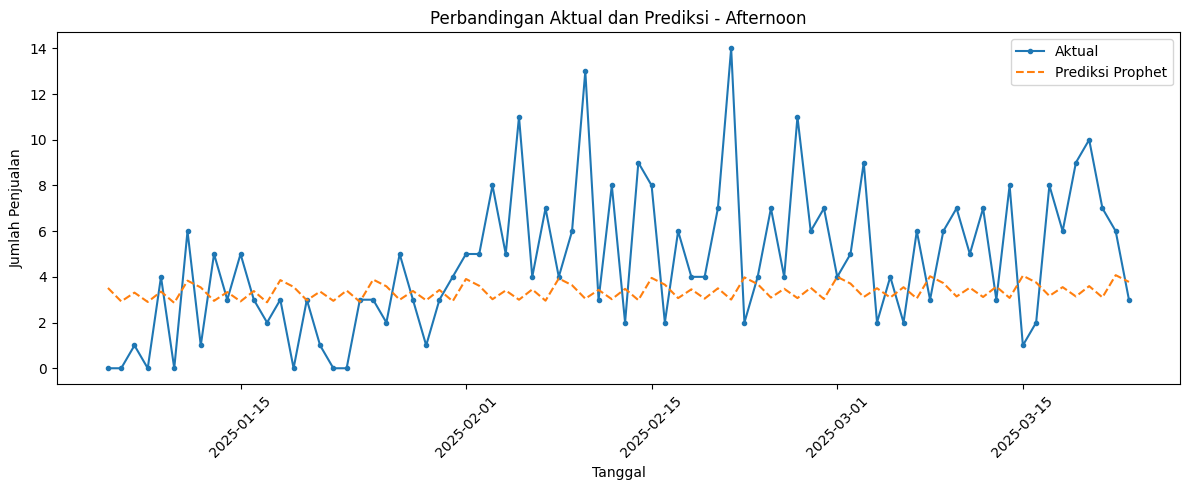

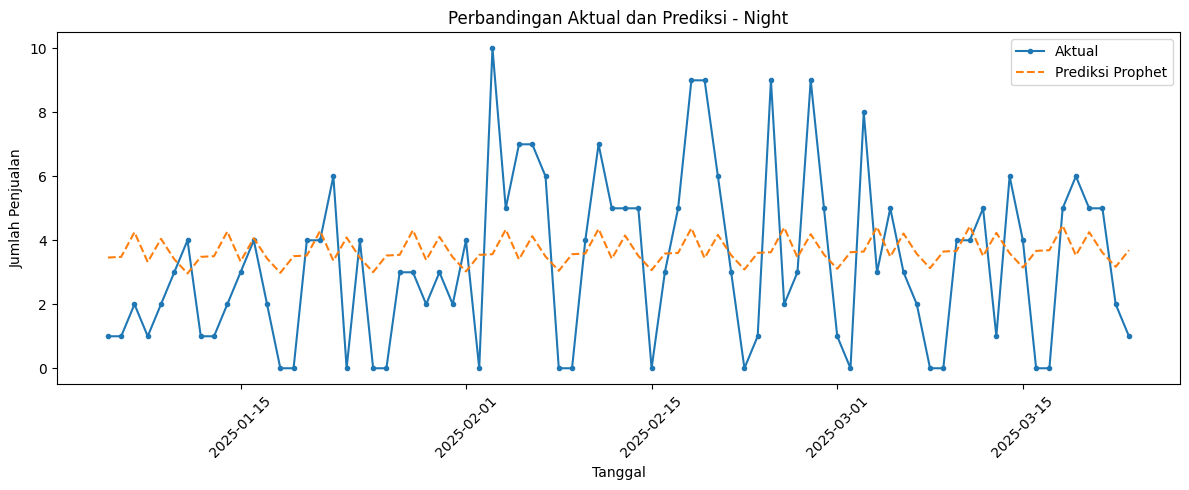

In [54]:
for waktu in kategori_waktu:

    hasil = hasil_testing[waktu]

    plt.figure(figsize=(12, 5))

    plt.plot(
        hasil['ds'],
        hasil['Aktual'],
        label='Aktual',
        marker='o',
        markersize=3
    )

    plt.plot(
        hasil['ds'],
        hasil['Prediksi'],
        label='Prediksi Prophet',
        linestyle='--'
    )

    plt.title(f'Perbandingan Aktual dan Prediksi - {waktu}')
    plt.xlabel('Tanggal')
    plt.ylabel('Jumlah Penjualan')
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

Prediksi beda code

In [51]:
from prophet import Prophet
import pandas as pd

hasil_prediksi = []

for waktu in kategori_waktu:

    # Mengambil data time series kategori waktu
    data = data_per_waktu[waktu].copy()

    # Membuat dan melatih model Prophet
    model = Prophet()
    model.fit(data)

    # Membuat tanggal untuk prediksi 1 hari ke depan
    future = model.make_future_dataframe(
        periods=1,
        freq='D'
    )

    # Melakukan prediksi
    forecast = model.predict(future)

    # Mengambil hasil prediksi tanggal berikutnya
    prediksi = forecast.iloc[-1]

    hasil_prediksi.append({
        'Kategori_Waktu': waktu,
        'Tanggal_Prediksi': prediksi['ds'],
        'Prediksi_Penjualan': max(0, round(prediksi['yhat'])),
        'Batas_Bawah': prediksi['yhat_lower'],
        'Batas_Atas': prediksi['yhat_upper']
    })

# Menampilkan hasil prediksi
hasil_prediksi = pd.DataFrame(hasil_prediksi)

display(hasil_prediksi)

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


,Kategori_Waktu,Tanggal_Prediksi,Prediksi_Penjualan,Batas_Bawah,Batas_Atas
0,Morning,2025-03-24,5,1.420535,7.331301
1,Afternoon,2025-03-24,5,1.582460,7.938942
2,Night,2025-03-24,4,0.580236,6.911751
